# EN3160 Assignment 02: Fitting and Alignment

**Name:** M.R.A. Hakam  
**Index No:** 230224V  
**GitHub:** [github.com/hakammra](https://github.com/hakammra)

### Introduction
this notebook implements the four tasks Assignment 02: scale-space blob detection using the Laplacian of Gaussian (LoG), sequential line and circle fitting using custom RANSAC implementations, planar homography estimation for image compositing, and SIFT feature matching for PCB image alignment and defect/parallax inspection.

In [1]:
from pathlib import Path
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter
from scipy.optimize import minimize

ROOT = Path.cwd()
cv.setNumThreads(2)


### Question 1: Laplacian of Gaussian (LoG) Blob Detection

adapted from the scale-space blob detection example in e_edges_corners_and_blobs.ipynb (Cells 16–22). To achieve scale invariance across different blob sizes, we use the scale-normalized Laplacian of Gaussian kernel:
$$\sigma^2 \nabla^2 G(x, y; \sigma) = \frac{x^2 + y^2 - 2\sigma^2}{2\pi \sigma^4} \exp\left(-\frac{x^2 + y^2}{2\sigma^2}\right)$$
For a dark circular blob of radius $r$, the filter response reaches its maximum at scale $\sigma = r / \sqrt{2}$, so the characteristic blob radius is $r = \sqrt{2}\sigma$.

The sunflower field image is loaded at quarter resolution (cv.IMREAD_REDUCED_COLOR_4, giving $360 \times 360$ pixels) and filtered over $\sigma \in [1.0, 12.0]$ with step $0.5$ ($23$ scales). We detect 3D local maxima in $(x, y, \sigma)$ using a $3 \times 3 \times 3$ neighborhood filter above a response threshold of $0.22$, verify the surrounding yellow petal ring in HSV space (at least $35\%$ yellow pixels in the annulus $[r, 2.2r]$) to reject dark background foliage, and apply non-maximum suppression to remove overlapping detections.

In [2]:
# Scale-normalized LoG kernel and 3D scale-space construction
def normalized_log_kernel(sigma):
    half_width = int(np.ceil(3 * sigma))
    coords = np.arange(-half_width, half_width + 1, dtype=np.float64)
    x, y = np.meshgrid(coords, coords)
    r2 = x ** 2 + y ** 2
    kernel = (r2 / sigma ** 2 - 2) * np.exp(-r2 / (2 * sigma ** 2)) / (2 * np.pi * sigma ** 2)
    return kernel.astype(np.float32)

def build_scale_space(gray_img, sigmas):
    responses = [cv.filter2D(gray_img, cv.CV_32F, normalized_log_kernel(s)) for s in sigmas]
    return np.stack(responses, axis=-1)

def scale_space_extrema(scale_space, response_threshold=0.22):
    local_max = maximum_filter(scale_space, size=3, mode='nearest')
    maxima = (scale_space == local_max) & (scale_space >= response_threshold)
    # Exclude boundary scales where 3D neighborhood is incomplete
    maxima[:, :, 0] = False
    maxima[:, :, -1] = False
    coords = np.argwhere(maxima)
    return sorted(coords, key=lambda pt: float(scale_space[tuple(pt)]), reverse=True)

def yellow_ring_fraction(yellow_mask, x, y, radius, outer_factor=2.2):
    h, w = yellow_mask.shape
    half = int(np.ceil(outer_factor * radius))
    x0, x1 = max(0, x - half), min(w, x + half + 1)
    y0, y1 = max(0, y - half), min(h, y + half + 1)
    rows, cols = np.ogrid[y0:y1, x0:x1]
    dist2 = (cols - x) ** 2 + (rows - y) ** 2
    ring = (dist2 > radius ** 2) & (dist2 <= (outer_factor * radius) ** 2)
    return float(yellow_mask[y0:y1, x0:x1][ring].mean())

sunflower_img = cv.imread(str(ROOT / 'images/the_berry_farms_sunflower_field.jpeg'), cv.IMREAD_REDUCED_COLOR_4)
sigma_values = np.arange(1.0, 12.5, 0.5)
print(f"Image size: {sunflower_img.shape[1]} x {sunflower_img.shape[0]} pixels")
print(f"Sigma range: {sigma_values[0]:g} to {sigma_values[-1]:g} (step 0.5, {len(sigma_values)} scales)")


Image size: 360 x 360 pixels
Sigma range: 1 to 12 (step 0.5, 23 scales)


Total detected sunflower centers: 65
Rank      x      y    Radius (px)    Sigma
   1    282    338          10.61      7.5
   2    106    255           8.49      6.0
   3    179    327           8.49      6.0
   4    178    261           7.78      5.5
   5    161    290           6.36      4.5


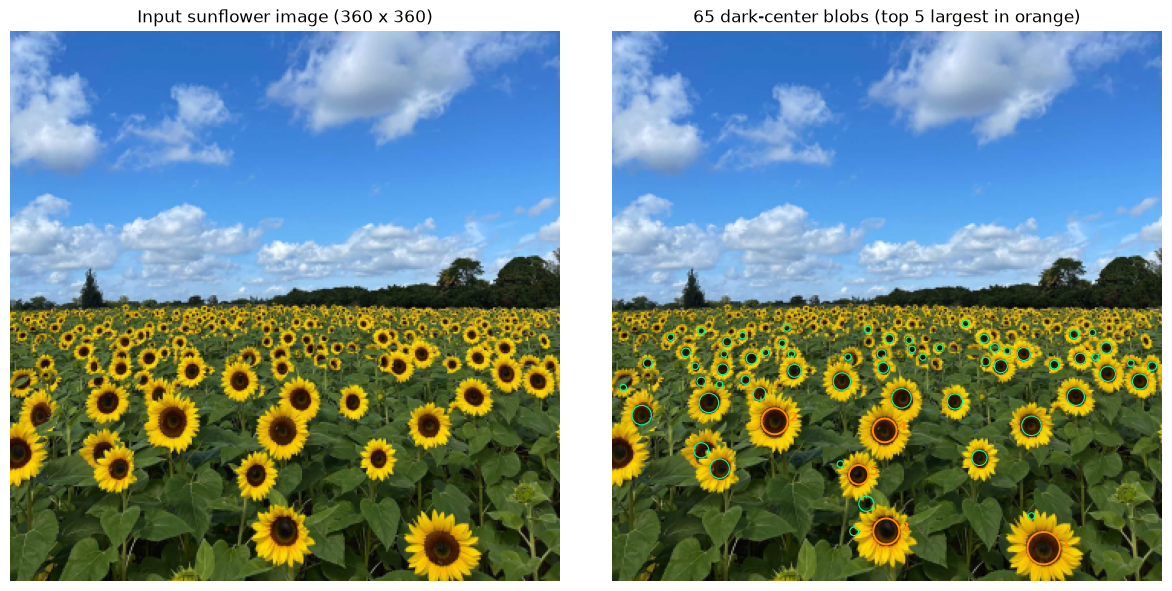

In [3]:
# Detect sunflower centers across position and scale
def detect_sunflowers(image, sigmas):
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0
    scale_space = build_scale_space(gray, sigmas)
    candidates = scale_space_extrema(scale_space, response_threshold=0.22)

    # HSV mask for yellow sunflower petals surrounding dark centers
    hsv = cv.cvtColor(image, cv.COLOR_BGR2HSV)
    yellow_mask = cv.inRange(hsv, np.array([15, 100, 120]), np.array([38, 255, 255])) > 0
    h, w = gray.shape
    circles = []

    for row, col, scale_idx in candidates:
        x, y = int(col), int(row)
        sigma = float(sigmas[scale_idx])
        radius = float(np.sqrt(2) * sigma)

        # Skip detections clipped by the image border
        if x < radius or y < radius or x + radius >= w or y + radius >= h:
            continue
        if yellow_ring_fraction(yellow_mask, x, y, radius) < 0.35:
            continue
        # Suppress overlapping detections on the same flower center
        if any(np.hypot(x - c['x'], y - c['y']) < 0.6 * (radius + c['radius']) for c in circles):
            continue

        circles.append({
            'x': x,
            'y': y,
            'radius': radius,
            'sigma': sigma,
            'response': float(scale_space[row, col, scale_idx]),
        })

    circles.sort(key=lambda c: (-c['radius'], -c['response']))
    return circles

sunflower_circles = detect_sunflowers(sunflower_img, sigma_values)

rgb = cv.cvtColor(sunflower_img, cv.COLOR_BGR2RGB)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.8), layout='constrained')
axes[0].imshow(rgb)
axes[0].set_title('Input sunflower image (360 x 360)')
axes[1].imshow(rgb)
axes[1].set_title(f'{len(sunflower_circles)} dark-center blobs (top 5 largest in orange)')

for idx, c in enumerate(sunflower_circles):
    color = '#ff8c00' if idx < 5 else '#00ff99'
    lw = 1.4 if idx < 5 else 0.8
    axes[1].add_patch(plt.Circle((c['x'], c['y']), c['radius'], fill=False, color=color, linewidth=lw))
    if idx < 5:
        axes[1].text(c['x'] + c['radius'] + 1, c['y'], str(idx + 1), color=color, fontsize=9, weight='bold')

for ax in axes:
    ax.set_axis_off()
plt.show()

print(f"Total detected sunflower centers: {len(sunflower_circles)}")
print("Rank      x      y    Radius (px)    Sigma")
for idx, c in enumerate(sunflower_circles[:5], 1):
    print(f"{idx:4d}  {c['x']:5d}  {c['y']:5d}      {c['radius']:9.2f}  {c['sigma']:7.1f}")


#### Results and Discussion
The scale-space LoG detector identifies **65** sunflower centers in the $360 \times 360$ reduced image. The largest detected circle is centered at $(x, y) = (282, 338)$ in the foreground with scale $\sigma = 7.5$ and radius $r = \sqrt{2}\sigma = 10.61\text{ px}$, followed by two foreground flowers of radius $8.49\text{ px}$ ($\sigma = 6.0$) at $(106, 255)$ and $(179, 327)$. Because the LoG filter responds to the high-contrast dark disc rather than the outer petals, each circle tightly bounds the central seed head. Prominent foreground flowers are captured reliably, whereas very distant flowers near the horizon fall below the minimum scale $\sigma = 1.0$ or merge during non-maximum suppression.

### Question 2: Line and Circle Fitting with RANSAC

Using the point generator from Listing 1 of the assignment brief (seed = 0), we generate $N = 100$ noisy points consisting of $50$ circle points around center $(2, 3)$ with radius $r = 10$ (radial noise $\sigma_c = r/16 = 0.625$) and $50$ line points along $y = -x + 2$ (vertical noise $\sigma_l = 1.0$, corresponding to perpendicular noise $\sigma_l / \sqrt{2} \approx 0.71$).

Both RANSAC loops are implemented from scratch following f_fitting.ipynb:
- **Line RANSAC:** Samples $2$ distinct points to form a unit-normal line $ax + by - d = 0$ with $\|[a, b]^\top\| = 1$. Inliers are selected using perpendicular distance threshold $t_{\text{line}} = 1.4$ (approx. $2\sigma_{\perp}$) and minimum consensus $40$ over $500$ iterations. The best inlier set is refined via Total Least Squares (SVD).
- **Circle RANSAC:** After subtracting the line inliers, samples $3$ non-collinear points to solve for the circumcircle $(x_0, y_0, r)$. Inliers are selected using radial distance $|\|(x - x_0, y - y_0)\|_2 - r| \le 1.25$ ($2\sigma_c$) and minimum consensus $30$ over $500$ iterations, then refined using scipy.optimize.minimize (L-BFGS-B).

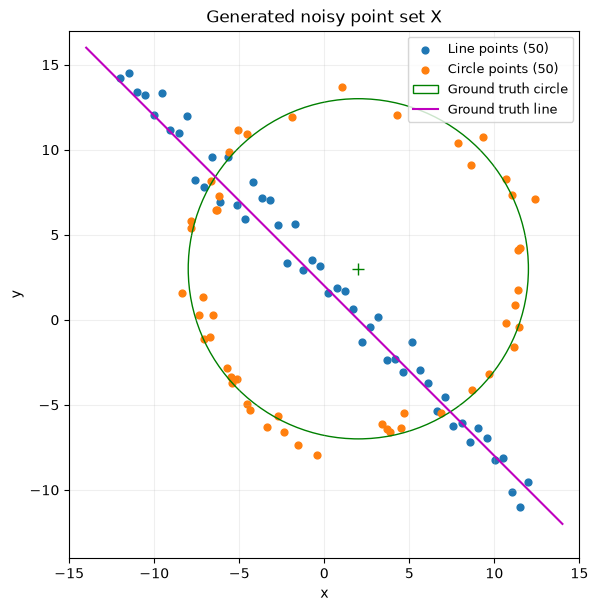

In [4]:
# Listing 1: Generation of a noisy point set conforming to a line and a circle
np.random.seed(0)
N = 100
half_n = N // 2
r_gt = 10
x0_gt, y0_gt = 2, 3  # Ground truth center
s_circ = r_gt / 16
t = np.random.uniform(0, 2 * np.pi, half_n)
n = s_circ * np.random.randn(half_n)
x, y = x0_gt + (r_gt + n) * np.cos(t), y0_gt + (r_gt + n) * np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

s_line = 1.0
m_gt, b_gt = -1, 2
x = np.linspace(-12, 12, half_n)
y = m_gt * x + b_gt + s_line * np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
points = np.vstack((X_circ, X_line))  # All 100 points

fig, ax = plt.subplots(figsize=(6, 6), layout='constrained')
ax.scatter(X_line[:, 0], X_line[:, 1], s=24, label='Line points (50)')
ax.scatter(X_circ[:, 0], X_circ[:, 1], s=24, label='Circle points (50)')
ax.add_patch(plt.Circle((x0_gt, y0_gt), r_gt, color='g', fill=False, label='Ground truth circle'))
ax.plot(x0_gt, y0_gt, '+', color='g', markersize=8)
x_vals = np.array([-14, 14])
ax.plot(x_vals, m_gt * x_vals + b_gt, color='m', label='Ground truth line')
ax.set(xlim=(-15, 15), ylim=(-14, 17), xlabel='x', ylabel='y', title='Generated noisy point set X')
ax.set_aspect('equal')
ax.grid(alpha=0.2)
ax.legend(loc='upper right', fontsize=9)
plt.show()


In [5]:
# Part (a): Custom RANSAC for unit-normal line fitting
def line_from_points(pts):
    direction = pts[1] - pts[0]
    length = np.linalg.norm(direction)
    if length < 1e-10:
        raise ValueError("Coincident points")
    normal = np.array([direction[1], -direction[0]]) / length
    model = np.append(normal, normal @ pts[0])
    return -model if model[2] < 0 else model

def line_errors(pts, model):
    return np.abs(pts @ model[:2] - model[2])

def fit_line_tls(pts):
    # Total least squares via SVD guarantees unit normal ||[a, b]|| = 1
    center = pts.mean(axis=0)
    _, _, vt = np.linalg.svd(pts - center, full_matrices=False)
    normal = vt[-1]
    model = np.append(normal, normal @ center)
    return -model if model[2] < 0 else model

def ransac_line(pts, threshold=1.4, min_inliers=40, iterations=500, seed=1):
    rng = np.random.default_rng(seed)
    best = None
    best_score = (-1, -np.inf)

    for it in range(iterations):
        sample = rng.choice(len(pts), 2, replace=False)
        try:
            sample_model = line_from_points(pts[sample])
        except ValueError:
            continue

        sample_mask = line_errors(pts, sample_model) <= threshold
        if sample_mask.sum() < min_inliers:
            continue

        # Iterative TLS refinement on consensus set
        inliers = sample_mask.copy()
        for _ in range(10):
            model = fit_line_tls(pts[inliers])
            updated = line_errors(pts, model) <= threshold
            if updated.sum() < min_inliers or np.array_equal(updated, inliers):
                break
            inliers = updated

        errors = line_errors(pts, model)
        inliers = errors <= threshold
        count = int(inliers.sum())
        if count < min_inliers:
            continue

        mse = float(np.mean(errors[inliers] ** 2))
        score = (count, -mse)
        if score > best_score:
            best_score = score
            best = {
                'model': model,
                'sample_model': sample_model,
                'sample_indices': sample,
                'inlier_indices': np.flatnonzero(inliers),
                'inlier_count': count,
                'inlier_rmse': float(np.sqrt(mse)),
            }
    return best

line = ransac_line(points)
print("Estimated line [a, b, d]:", np.round(line['model'], 4))
print(f"Unit normal check ||[a, b]||: {np.linalg.norm(line['model'][:2]):.4f}")
print(f"Line consensus inliers: {line['inlier_count']} / {len(points)} (RMSE: {line['inlier_rmse']:.4f})")


Estimated line [a, b, d]: [0.721  0.693  1.5724]
Unit normal check ||[a, b]||: 1.0000
Line consensus inliers: 54 / 100 (RMSE: 0.6706)


In [6]:
# Part (b): Subtract line consensus and fit circle on remnant using custom RANSAC
def circle_from_points(pts):
    offsets = pts[1:] - pts[0]
    matrix = 2.0 * offsets
    if np.linalg.cond(matrix) > 1e8:
        raise ValueError("Collinear points")
    rhs = np.sum(offsets ** 2, axis=1)
    rel_center = np.linalg.solve(matrix, rhs)
    center = pts[0] + rel_center
    radius = np.linalg.norm(rel_center)
    return np.append(center, radius)

def circle_errors(pts, model):
    return np.abs(np.linalg.norm(pts - model[:2], axis=1) - model[2])

def fit_circle(pts, init_model):
    def objective(m):
        residuals = np.linalg.norm(pts - m[:2], axis=1) - m[2]
        return float(residuals @ residuals)

    res = minimize(
        objective,
        init_model,
        method='L-BFGS-B',
        bounds=[(None, None), (None, None), (1e-8, None)],
        options={'ftol': 1e-12, 'gtol': 1e-7, 'maxiter': 300},
    )
    return res.x

def ransac_circle(pts, threshold=1.25, min_inliers=30, iterations=500, seed=2):
    rng = np.random.default_rng(seed)
    best = None
    best_score = (-1, -np.inf)

    for it in range(iterations):
        sample = rng.choice(len(pts), 3, replace=False)
        try:
            sample_model = circle_from_points(pts[sample])
        except (ValueError, np.linalg.LinAlgError):
            continue

        sample_mask = circle_errors(pts, sample_model) <= threshold
        if sample_mask.sum() < min_inliers:
            continue

        inliers = sample_mask.copy()
        model = sample_model.copy()
        for _ in range(10):
            model = fit_circle(pts[inliers], model)
            updated = circle_errors(pts, model) <= threshold
            if updated.sum() < min_inliers or np.array_equal(updated, inliers):
                break
            inliers = updated

        errors = circle_errors(pts, model)
        inliers = errors <= threshold
        count = int(inliers.sum())
        if count < min_inliers:
            continue

        mse = float(np.mean(errors[inliers] ** 2))
        score = (count, -mse)
        if score > best_score:
            best_score = score
            best = {
                'model': model,
                'sample_model': sample_model,
                'sample_indices': sample,
                'inlier_indices': np.flatnonzero(inliers),
                'inlier_count': count,
                'inlier_rmse': float(np.sqrt(mse)),
            }
    return best

remaining_idx = np.setdiff1d(np.arange(len(points)), line['inlier_indices'])
circle = ransac_circle(points[remaining_idx])
circle['sample_indices'] = remaining_idx[circle['sample_indices']]
circle['inlier_indices'] = remaining_idx[circle['inlier_indices']]

print(f"Remnant points after removing line consensus: {len(remaining_idx)}")
print("Estimated circle [x0, y0, r]:", np.round(circle['model'], 4))
print(f"Circle consensus inliers: {circle['inlier_count']} / {len(remaining_idx)} (RMSE: {circle['inlier_rmse']:.4f})")


Remnant points after removing line consensus: 46
Estimated circle [x0, y0, r]: [1.8982 3.0101 9.8314]
Circle consensus inliers: 44 / 46 (RMSE: 0.5311)


Fitting order         Line inliers    Circle inliers    Circle [x0, y0, r]
Line then circle                54                44    [1.898 3.01  9.831]
Circle then line                41                57    [1.902 3.018 9.88 ]


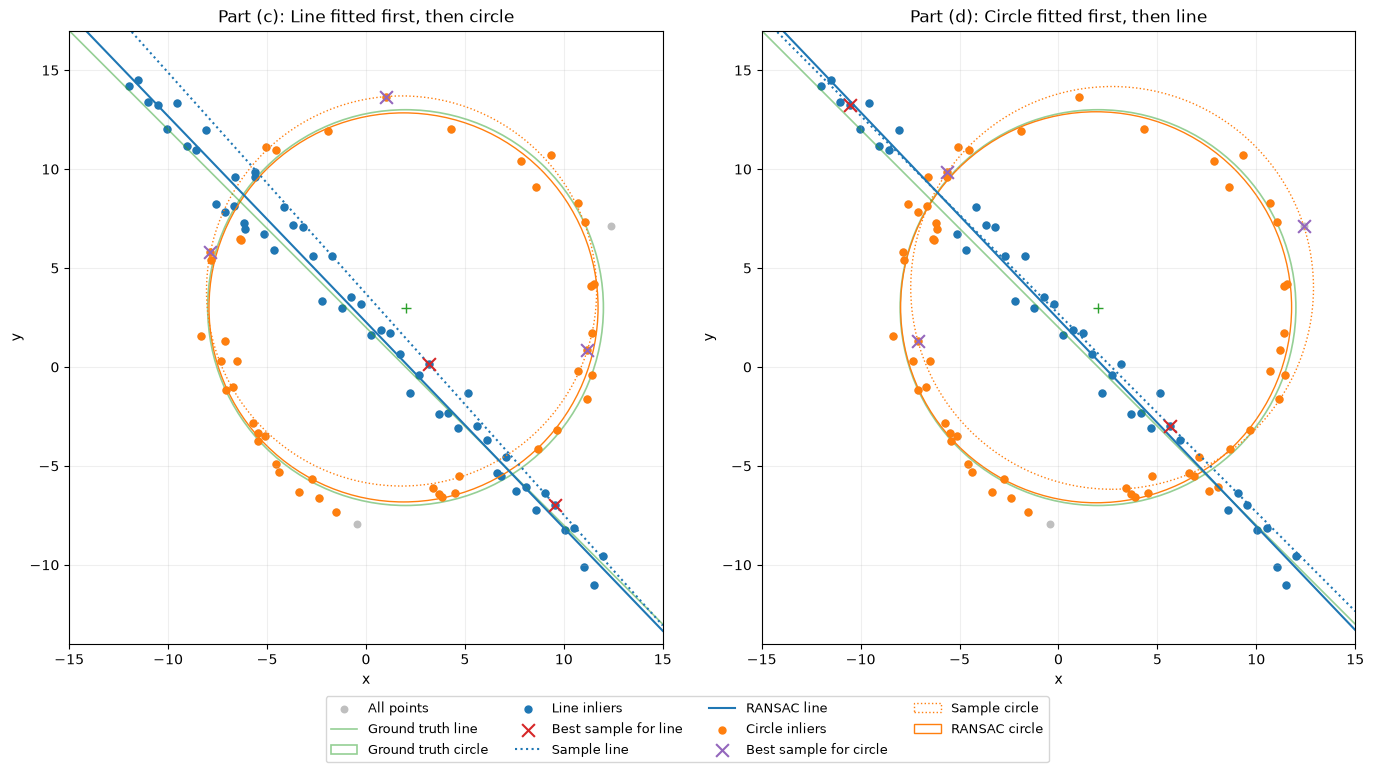

In [7]:
# Parts (c) and (d): Combined plot and comparison with circle-first fitting order
def fit_circle_then_line(pts):
    circ_first = ransac_circle(pts)
    rem_idx = np.setdiff1d(np.arange(len(pts)), circ_first['inlier_indices'])
    line_second = ransac_line(pts[rem_idx])
    line_second['sample_indices'] = rem_idx[line_second['sample_indices']]
    line_second['inlier_indices'] = rem_idx[line_second['inlier_indices']]
    return {'circle': circ_first, 'line': line_second}

def plot_line_model(ax, model, label, color, linestyle='solid'):
    a, b, d = model
    if abs(b) < 1e-10:
        ax.axvline(d / a, label=label, color=color, linestyle=linestyle)
    else:
        x_vals = np.array([-15, 15])
        ax.plot(x_vals, (d - a * x_vals) / b, label=label, color=color, linestyle=linestyle)

def plot_fitting_order(ax, pts, line_res, circ_res, title):
    ax.scatter(pts[:, 0], pts[:, 1], s=22, color='0.75', label='All points')

    # Ground truth models for reference (as in Figure 1 of brief)
    x_gt = np.array([-15, 15])
    ax.plot(x_gt, m_gt * x_gt + b_gt, color='tab:green', alpha=0.5, linewidth=1.2, label='Ground truth line')
    ax.add_patch(plt.Circle((x0_gt, y0_gt), r_gt, fill=False, color='tab:green', alpha=0.5, linewidth=1.2, label='Ground truth circle'))
    ax.plot(x0_gt, y0_gt, '+', color='tab:green', markersize=7)

    for res, name, color, sample_color in [
        (line_res, 'Line', 'tab:blue', 'tab:red'),
        (circ_res, 'Circle', 'tab:orange', 'tab:purple'),
    ]:
        ax.scatter(*pts[res['inlier_indices']].T, s=25, color=color, label=f'{name} inliers')
        ax.scatter(*pts[res['sample_indices']].T, s=85, marker='x', color=sample_color,
                   label=f'Best sample for {name.lower()}', zorder=5)
        for key, lbl, style in [
            ('sample_model', f'Sample {name.lower()}', 'dotted'),
            ('model', f'RANSAC {name.lower()}', 'solid'),
        ]:
            m = res[key]
            if name == 'Line':
                plot_line_model(ax, m, lbl, color, style)
            else:
                ax.add_patch(plt.Circle(m[:2], m[2], fill=False, label=lbl, color=color, linestyle=style))

    ax.set(xlim=(-15, 15), ylim=(-14, 17), xlabel='x', ylabel='y', title=title)
    ax.set_aspect('equal')
    ax.grid(alpha=0.2)

reverse_fit = fit_circle_then_line(points)
print("Fitting order         Line inliers    Circle inliers    Circle [x0, y0, r]")
print(f"Line then circle      {line['inlier_count']:12d}    {circle['inlier_count']:14d}    {np.round(circle['model'], 3)}")
print(f"Circle then line      {reverse_fit['line']['inlier_count']:12d}    {reverse_fit['circle']['inlier_count']:14d}    {np.round(reverse_fit['circle']['model'], 3)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 7.5))
plot_fitting_order(axes[0], points, line, circle, 'Part (c): Line fitted first, then circle')
plot_fitting_order(axes[1], points, reverse_fit['line'], reverse_fit['circle'], 'Part (d): Circle fitted first, then line')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, fontsize=9.5)
fig.tight_layout(rect=(0, 0.13, 1, 1))
plt.show()


#### Results and Discussion
- **Line-first fitting (Parts a–c):** RANSAC estimates the unit-normal line $[a, b, d] = [0.7210, 0.6930, 1.5724]$ (true normal $[1/\sqrt{2}, 1/\sqrt{2}, 2/\sqrt{2}] \approx [0.7071, 0.7071, 1.4142]$), capturing all $50$ line points plus $4$ circle points near the two line–circle intersections ($54$ inliers total). Subtracting these leaves $46$ remnant points, from which circle RANSAC recovers $44$ inliers and refines the circle to center $(1.8982, 3.0101)$ and radius $r = 9.8314$, matching the ground truth $(2, 3), r = 10$ closely.
- **What happens if we fit the circle first (Part d):** Because a circle has $3$ degrees of freedom (more flexibility than a $2$-DoF line) and crosses the line twice, fitting the circle first absorbs $57$ inliers—including $9$ collinear line points near the intersection bands. This leaves only $43$ points for the subsequent line fit ($41$ line inliers recovered). On noisier datasets or stricter consensus thresholds, fitting the higher-capacity curve first can strip away enough collinear points that the second-stage line RANSAC fails to reach its minimum consensus threshold.

### Question 3: Planar Homography and Image Compositing

To superimpose an overlay image onto a planar surface in a background scene, we select four target corners $(x_i, y_i)$ in clockwise order (top-left, top-right, bottom-right, bottom-left) and compute the $3 \times 3$ projective homography $H$ mapping the source image corners $\{(0,0), (W-1,0), (W-1,H-1), (0,H-1)\}$ to the target quad via cv.getPerspectiveTransform. A warped binary mask restricts alpha blending strictly to the projected planar surface so surrounding scene pixels remain untouched.

**Rationale for chosen image pairs:**
1. **Fruit label on a cereal box (box_in_scene.png + fruits.jpg):** Demonstrates projective foreshortening on an oblique tilted packaging face in a cluttered tabletop scene, where blending at opacity $0.80$ preserves underlying surface shading.
2. **Butterfly mural on a street wall (graf1.png + butterfly.jpg):** Uses the planar wall from the Oxford VGG viewpoint dataset to project a wide mural across a strongly slanted architectural facade (opacity $0.85$).

In [8]:
# Interactive 4-point corner selection helper and saved coordinates for reproducibility
def select_corners(image):
    h, w = image.shape[:2]
    scale = min(1000 / w, 700 / h, 1.0)
    preview = cv.resize(image, None, fx=scale, fy=scale)
    pts = []
    title = "Click 4 corners: TL, TR, BR, BL (Enter=save, R=reset)"

    def redraw():
        frame = preview.copy()
        for idx, pt in enumerate(pts, 1):
            pos = tuple(np.round(np.array(pt) * scale).astype(int))
            cv.circle(frame, pos, 5, (0, 255, 255), -1)
            cv.putText(frame, str(idx), pos, cv.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
        if len(pts) == 4:
            contour = np.round(np.array(pts) * scale).astype(np.int32)
            cv.polylines(frame, [contour], True, (0, 255, 255), 2)
        cv.imshow(title, frame)

    def on_click(event, x, y, flags, param):
        if event == cv.EVENT_LBUTTONDOWN and len(pts) < 4:
            pts.append([x / scale, y / scale])
            redraw()

    cv.namedWindow(title, cv.WINDOW_AUTOSIZE)
    cv.setMouseCallback(title, on_click)
    redraw()
    try:
        while True:
            key = cv.waitKey(20) & 0xFF
            if key in (ord('r'), ord('R')):
                pts.clear()
                redraw()
            elif key in (10, 13) and len(pts) == 4:
                return np.asarray(pts, dtype=np.float32)
    finally:
        cv.destroyAllWindows()

examples = [
    {
        'background': 'images/compositing/box_in_scene.png',
        'overlay': 'images/compositing/fruits.jpg',
        'corners': [[121, 177], [228, 186], [217, 266], [103, 252]],
        'opacity': 0.80,
        'title': 'Fruit on box',
    },
    {
        'background': 'images/compositing/graf1.png',
        'overlay': 'images/compositing/butterfly.jpg',
        'corners': [[80, 60], [697, 92], [671, 460], [112, 487]],
        'opacity': 0.85,
        'title': 'Butterfly on wall',
    },
]
select_new_points = False


Fruit on box (corners=[[121, 177], [228, 186], [217, 266], [103, 252]], opacity=0.8):
[[ 1.867e-01 -5.180e-02  1.210e+02]
 [-9.000e-04  1.217e-01  1.770e+02]
 [-1.000e-04 -1.000e-04  1.000e+00]]
Butterfly on wall (corners=[[80, 60], [697, 92], [671, 460], [112, 487]], opacity=0.85):
[[1.4928e+00 1.2530e-01 8.0000e+01]
 [9.6600e-02 1.3559e+00 6.0000e+01]
 [3.0000e-04 3.0000e-04 1.0000e+00]]


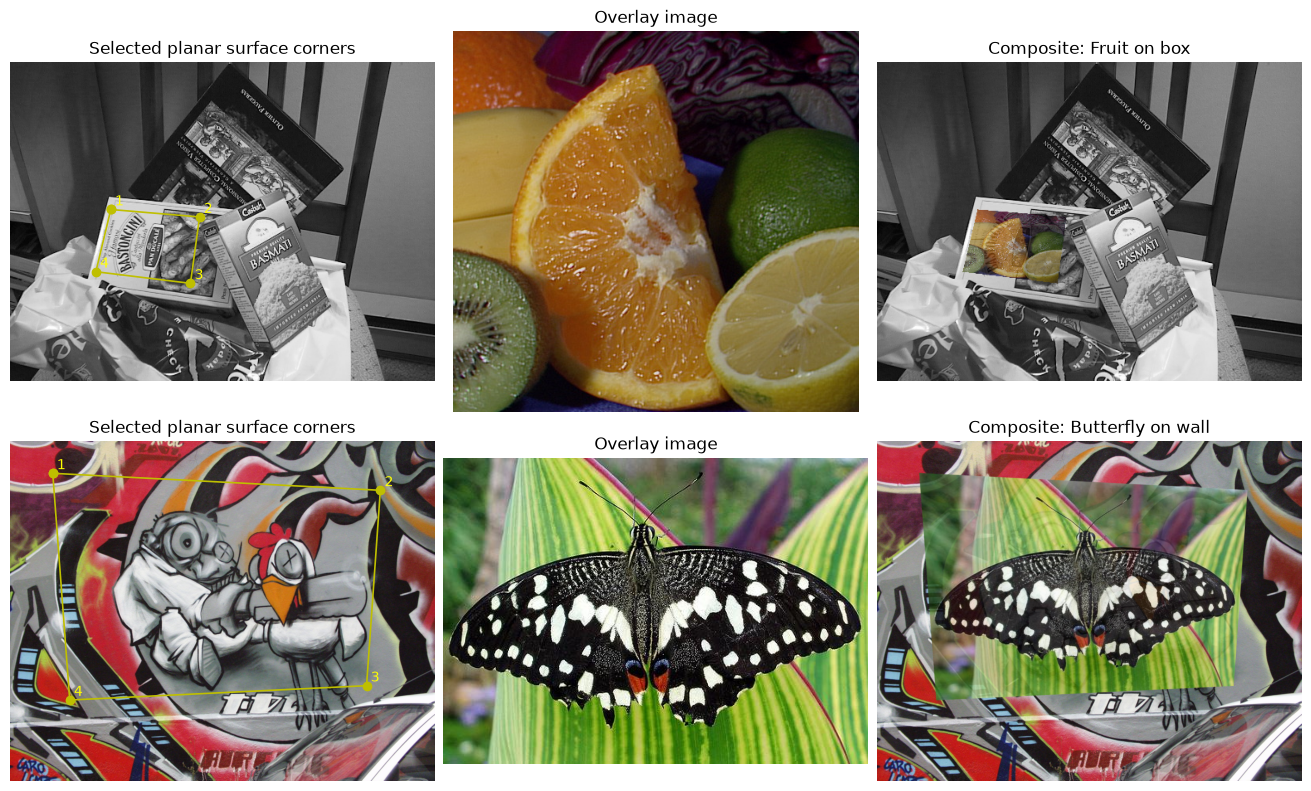

In [9]:
# Compute planar homography, warp overlay + mask, and blend onto background
def composite_overlay(background, overlay, corners, opacity=0.8):
    corners = np.asarray(corners, dtype=np.float32)
    h, w = overlay.shape[:2]
    src_corners = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
    H = cv.getPerspectiveTransform(src_corners, corners)

    if overlay.shape[2] == 4:
        alpha = overlay[:, :, 3].astype(np.float32) / 255.0
    else:
        alpha = np.ones((h, w), dtype=np.float32)

    colors = overlay[:, :, :3].astype(np.float32) * alpha[:, :, None]
    dsize = (background.shape[1], background.shape[0])
    warped_colors = cv.warpPerspective(colors, H, dsize, flags=cv.INTER_LINEAR)
    coverage = cv.warpPerspective(alpha, H, dsize, flags=cv.INTER_LINEAR)

    blended = background.astype(np.float32) * (1.0 - opacity * coverage[:, :, None]) + opacity * warped_colors
    return np.clip(np.round(blended), 0, 255).astype(np.uint8), H, coverage

fig, axes = plt.subplots(2, 3, figsize=(13, 8), layout='constrained')
for row, ex in enumerate(examples):
    bg = cv.imread(str(ROOT / ex['background']))
    ov = cv.imread(str(ROOT / ex['overlay']), cv.IMREAD_UNCHANGED)
    pts = select_corners(bg) if select_new_points else np.float32(ex['corners'])
    comp, H, mask = composite_overlay(bg, ov, pts, ex['opacity'])

    print(f"{ex['title']} (corners={pts.astype(int).tolist()}, opacity={ex['opacity']}):")
    print(np.round(H, 4))

    axes[row, 0].imshow(cv.cvtColor(bg, cv.COLOR_BGR2RGB))
    closed = np.vstack([pts, pts[0]])
    axes[row, 0].plot(closed[:, 0], closed[:, 1], 'yo-', linewidth=1.2)
    for idx, pt in enumerate(pts, 1):
        axes[row, 0].annotate(str(idx), pt, xytext=(3, 3), textcoords='offset points', color='yellow')

    code = cv.COLOR_BGRA2RGBA if ov.shape[2] == 4 else cv.COLOR_BGR2RGB
    axes[row, 1].imshow(cv.cvtColor(ov, code))
    axes[row, 2].imshow(cv.cvtColor(comp, cv.COLOR_BGR2RGB))

    axes[row, 0].set_title('Selected planar surface corners')
    axes[row, 1].set_title('Overlay image')
    axes[row, 2].set_title(f"Composite: {ex['title']}")

for ax in axes.flat:
    ax.axis('off')
plt.show()


#### Results and Discussion
In both composites, $3 \times 3$ homography accurately foreshortens the rectangular overlay to match the perspective convergence of the target planar quad. Warping a separate coverage mask ensures that bilinear interpolation at the quad edges blends smoothly without introducing black border halos outside the selected region.

### Question 4: SIFT Feature Matching and PCB Alignment

Adapted from the SIFT feature matching pipeline in e_edges_corners_and_blobs.ipynb (Cells 23–24), replacing FLANN with cv.BFMatcher(cv.NORM_L2) as required by the assignment brief. For the template image AECC1.jpg and each of the five inspection boards (AAAA1.jpg, ADAD1.jpg, AECC2.jpg, AECC3.jpg, AECC4.jpg), we:
1. Extract SIFT keypoints and 128-D descriptors using cv.SIFT_create().
2. Match descriptors via BFMatcher.knnMatch(k=2) with Lowe's ratio test ($d_1 < 0.8 d_2$) and mutual nearest-neighbor verification.
3. Estimate the planar homography $H$ to AECC1.jpg using cv.findHomography(..., cv.RANSAC, 5.0).
4. Warp each PCB into the template frame and compute the absolute grayscale difference $|I_{\text{aligned}} - I_{\text{ref}}|$ over the valid overlap mask.

Reference template: AECC1.jpg (3539 SIFT keypoints)
Board       Matches    RANSAC Inliers    Inlier RMSE (px)
AAAA1            76                33              2.5042
ADAD1           236               175              1.2612
AECC2          1987              1881              0.7145
AECC3          2156              2050              0.6140
AECC4          1976              1885              0.7335


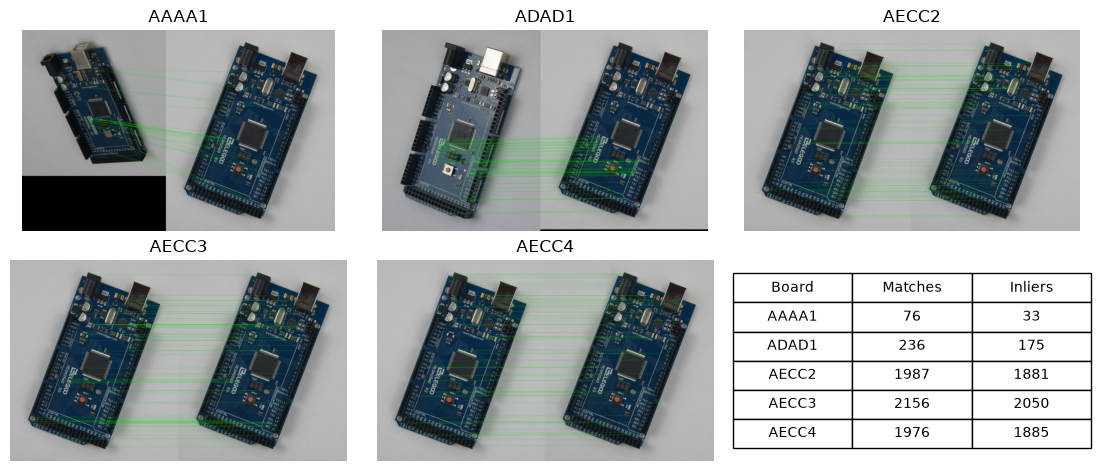

In [10]:
# Part (a) & (b): SIFT detection, BFMatcher ratio test, and RANSAC homography estimation
def detect_sift(image, sift, max_side=1000):
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    scale = min(max_side / max(gray.shape), 1.0)
    small = cv.resize(gray, None, fx=scale, fy=scale, interpolation=cv.INTER_AREA)
    kps, desc = sift.detectAndCompute(small, None)
    sx, sy = small.shape[1] / gray.shape[1], small.shape[0] / gray.shape[0]
    # Rescale keypoint coordinates back to full image resolution
    kps_full = [
        cv.KeyPoint(kp.pt[0] / sx, kp.pt[1] / sy, kp.size / np.sqrt(sx * sy),
                    kp.angle, kp.response, kp.octave, kp.class_id)
        for kp in kps
    ]
    return kps_full, desc, gray.shape

def estimate_pcb_homography(image, ref_features, sift, ratio=0.8, ransac_thresh=5.0):
    kps, desc, _ = detect_sift(image, sift)
    ref_kps, ref_desc, ref_shape = ref_features

    matcher = cv.BFMatcher(cv.NORM_L2)
    knn = matcher.knnMatch(desc, ref_desc, k=2)
    reverse = {m.queryIdx: m.trainIdx for m in matcher.match(ref_desc, desc)}
    matches = [
        pair[0] for pair in knn
        if len(pair) == 2 and pair[0].distance < ratio * pair[1].distance
        and reverse.get(pair[0].trainIdx) == pair[0].queryIdx
    ]

    src_pts = np.float32([kps[m.queryIdx].pt for m in matches])
    dst_pts = np.float32([ref_kps[m.trainIdx].pt for m in matches])
    cv.setRNGSeed(0)
    H, mask = cv.findHomography(src_pts, dst_pts, cv.RANSAC, ransac_thresh, maxIters=5000, confidence=0.995)
    inliers = mask.ravel().astype(bool)

    projected = cv.perspectiveTransform(src_pts[:, None, :], H)[:, 0, :]
    errors = np.linalg.norm(projected - dst_pts, axis=1)
    record = {
        'match_count': len(matches),
        'inlier_count': int(inliers.sum()),
        'inlier_rmse': float(np.sqrt(np.mean(errors[inliers] ** 2))),
        'inlier_mask': inliers,
        'homography': H,
    }
    return record, kps, matches

def draw_pcb_matches(image, ref_img, kps, ref_kps, matches, inlier_mask):
    inliers = [m for m, keep in zip(matches, inlier_mask) if keep]
    shown = sorted(inliers, key=lambda m: m.distance)[:80]
    view = cv.drawMatches(
        image, kps, ref_img, ref_kps, shown, None,
        matchColor=(0, 220, 0),
        flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
    )
    if view.shape[1] > 1400:
        s = 1400 / view.shape[1]
        view = cv.resize(view, None, fx=s, fy=s, interpolation=cv.INTER_AREA)
    return view

pcb_names = ['AAAA1.jpg', 'ADAD1.jpg', 'AECC2.jpg', 'AECC3.jpg', 'AECC4.jpg']
reference = cv.imread(str(ROOT / 'images/pcbs/AECC1.jpg'))
sift = cv.SIFT_create(nfeatures=5000)
ref_features = detect_sift(reference, sift)

pcb_results = {}
fig, axes = plt.subplots(2, 3, figsize=(11, 4.6), layout='constrained')
table_rows = []
print(f"Reference template: AECC1.jpg ({len(ref_features[0])} SIFT keypoints)")
print("Board       Matches    RANSAC Inliers    Inlier RMSE (px)")

for ax, name in zip(axes.flat, pcb_names):
    img = cv.imread(str(ROOT / 'images/pcbs' / name))
    rec, kps, matches = estimate_pcb_homography(img, ref_features, sift)
    view = draw_pcb_matches(img, reference, kps, ref_features[0], matches, rec['inlier_mask'])
    pcb_results[name] = {'image': img, 'record': rec}

    stem = Path(name).stem
    print(f"{stem:<10} {rec['match_count']:8d} {rec['inlier_count']:17d} {rec['inlier_rmse']:19.4f}")
    ax.imshow(cv.cvtColor(view, cv.COLOR_BGR2RGB))
    ax.set_title(stem)
    ax.axis('off')
    table_rows.append([stem, rec['match_count'], rec['inlier_count']])

axes.flat[-1].axis('off')
tbl = axes.flat[-1].table(cellText=table_rows, colLabels=['Board', 'Matches', 'Inliers'], loc='center', cellLoc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1, 1.4)
plt.show()


Board       Valid Overlap (%)    Mean Gray Difference (0-255)
AAAA1                   89.04                           28.26
ADAD1                   98.21                           31.17
AECC2                   98.44                            3.03
AECC3                   98.91                            2.91
AECC4                   98.53                            3.59


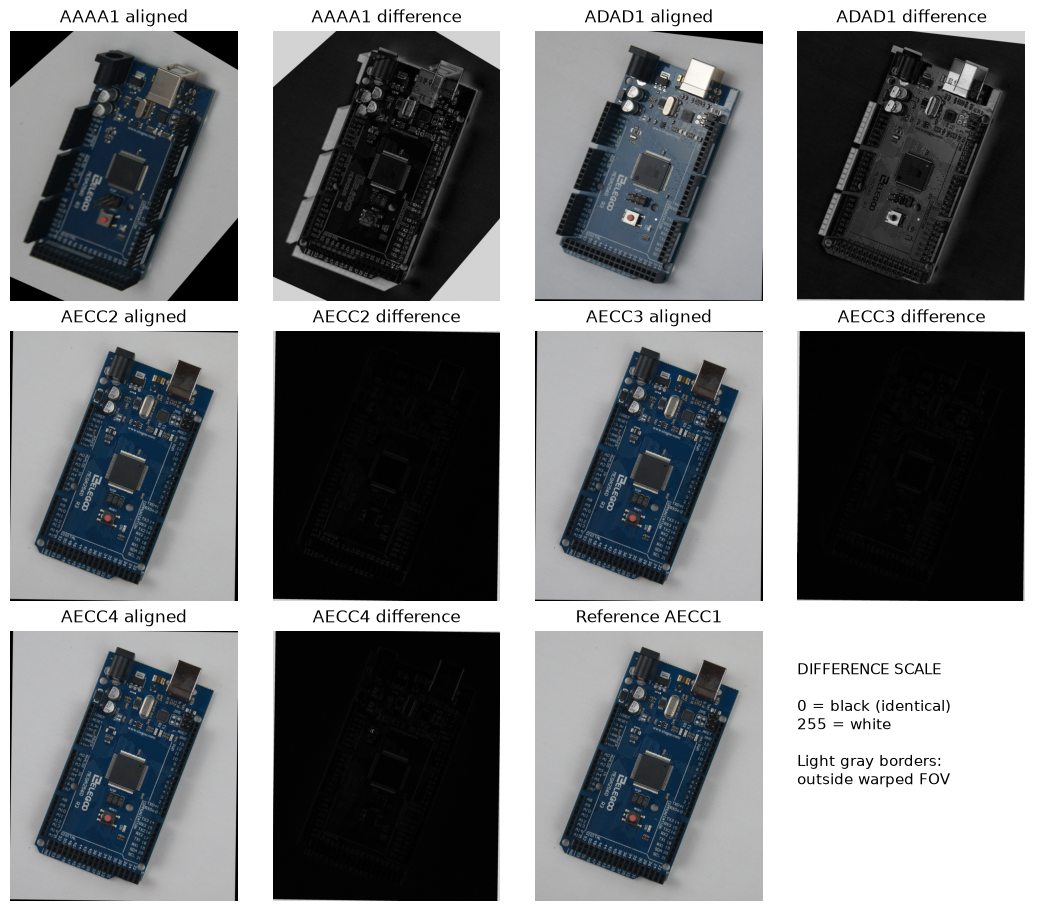

In [11]:
# Parts (c) & (d): Perspective warp and grayscale difference images across all 5 PCBs
def warp_and_difference(image, ref_img, H):
    dsize = (ref_img.shape[1], ref_img.shape[0])
    warped = cv.warpPerspective(image, H, dsize, flags=cv.INTER_LINEAR)
    support = cv.warpPerspective(np.ones(image.shape[:2], np.float32), H, dsize, flags=cv.INTER_LINEAR)
    valid = support >= 1.0 - 1e-6

    warped_gray = cv.cvtColor(warped, cv.COLOR_BGR2GRAY)
    ref_gray = cv.cvtColor(ref_img, cv.COLOR_BGR2GRAY)
    diff = cv.absdiff(warped_gray, ref_gray)
    diff[~valid] = 0
    return warped, diff, valid

fig, axes = plt.subplots(3, 4, figsize=(10.5, 9), layout='constrained')
print("Board       Valid Overlap (%)    Mean Gray Difference (0-255)")

for idx, name in enumerate(pcb_names):
    res = pcb_results[name]
    aligned, diff, valid = warp_and_difference(res['image'], reference, res['record']['homography'])
    res.update({'aligned': aligned, 'difference': diff, 'valid': valid})

    stem = Path(name).stem
    print(f"{stem:<10} {100.0 * valid.mean():18.2f} {diff[valid].mean():31.2f}")

    ax_align, ax_diff = axes.flat[2 * idx], axes.flat[2 * idx + 1]
    ax_align.imshow(cv.cvtColor(aligned, cv.COLOR_BGR2RGB))
    ax_align.set_title(f"{stem} aligned")

    masked_diff = np.ma.array(diff, mask=~valid)
    cmap = plt.get_cmap('gray').with_extremes(bad='lightgray')
    ax_diff.imshow(masked_diff, cmap=cmap, vmin=0, vmax=255)
    ax_diff.set_title(f"{stem} difference")

axes.flat[10].imshow(cv.cvtColor(reference, cv.COLOR_BGR2RGB))
axes.flat[10].set_title("Reference AECC1")
axes.flat[11].text(
    0.05, 0.65,
    "DIFFERENCE SCALE\n\n0 = black (identical)\n255 = white\n\nLight gray borders:\noutside warped FOV",
    fontsize=11, va='center', transform=axes.flat[11].transAxes,
)
for ax in axes.flat:
    ax.axis('off')
plt.show()


#### Results and Discussion (Including Part e)
- **Alignment performance:** AECC2, AECC3, and AECC4 were captured under similar camera distance and illumination as AECC1, yielding $1,976–2,156$ matches ($1,881–2,050$ RANSAC inliers, sub-pixel RMSE $0.61–0.73\text{ px}$) and very low mean grayscale differences ($2.91–3.59$). In contrast, AAAA1 ($33$ inliers, mean diff $28.26$) and ADAD1 ($175$ inliers, mean diff $31.17$) exhibit stronger perspective obliqueness and global exposure changes.
- **Why tall components (USB Type-B port, electrolytic capacitors, reset button) show high difference (Part e):** A $3 \times 3$ homography $H$ only models transformations of a **single flat 2D plane** (the fiberglass PCB substrate where most SIFT features lie). Tall 3D components protrude significantly above the board plane; when viewed from different camera angles, their tops project to different image locations relative to the substrate (**motion parallax**) and occlude different parts of the background. Furthermore, metallic housings (USB shield, capacitor tops) produce viewpoint-dependent **specular reflections** and cast directional **shadows** that do not warp consistently under a planar homography.

### Conclusion
scale-normalized LoG filtering reliably localized 65 sunflower centers across scale space without HoughCircles. Custom sequential RANSAC accurately separated the line and circle models while illustrating why model complexity and intersection geometry make fitting order critical. Finally, four-point and SIFT-based homographies demonstrated accurate planar warping alongside the physical parallax limitations of 2D projective alignment on 3D PCB components.